# 2층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 택시 요금 맞히기 (회귀)

**프롬프트**

> rides.csv에서 거리(distance_km)와 시간(duration_min)으로 요금(fare)을 맞히는 선형 회귀를 만들어 주세요.
> 학습 80% / 시험 20%로 나누고, 시험용으로 RMSE·MAE·R²를 출력하고
> 실제 요금과 예측 요금을 점으로 비교하는 그래프도 그려 주세요(그래프 글자는 영어).

RMSE: 1328 원
MAE : 1049 원
R²  : 0.921
기본요금(절편): 3006 / km당: 788 / 분당: 145


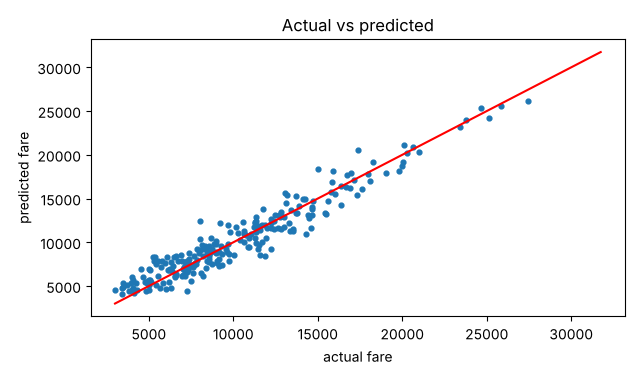

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/rides.csv")
X = df[["distance_km", "duration_min"]]
y = df["fare"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

print("RMSE:", round(mean_squared_error(y_test, pred) ** 0.5), "원")
print("MAE :", round(mean_absolute_error(y_test, pred)), "원")
print("R²  :", round(r2_score(y_test, pred), 3))
print("기본요금(절편):", round(model.intercept_), "/ km당:", round(model.coef_[0]), "/ 분당:", round(model.coef_[1]))

plt.scatter(y_test, pred, s=12)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
plt.xlabel("actual fare"); plt.ylabel("predicted fare"); plt.title("Actual vs predicted")
plt.show()

**박사의 한 줄 판단** — R² 0.921, 평균 1,049원 빗나감 — 본문 값과 몇 원 차이입니다. 기본요금 3,006원·km당 788원·분당 145원처럼 계수가 상식에 맞는지도 꼭 확인하세요.

## 실습 2 · 정확도의 함정 — 떠날 손님 맞히기 (분류)

**프롬프트**

> rides.csv로 손님 이탈(churned)을 맞히는 로지스틱 회귀를 만들어 주세요.
> 정확도만 보지 말고 혼동행렬과 재현율(떠난 손님 중 잡은 비율)도 보여 주세요.
> 그리고 class_weight="balanced"로 바꿨을 때와 비교해 주세요.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/rides.csv")
X = df[["distance_km", "duration_min", "hour", "is_weekend", "fare"]]
y = df["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for cw in [None, "balanced"]:
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw))
    pred = model.fit(X_train, y_train).predict(X_test)
    print("class_weight =", cw)
    print("  정확도:", round(accuracy_score(y_test, pred), 3), "/ 재현율:", round(recall_score(y_test, pred), 3))
    print("  혼동행렬 [[남음→남음, 남음→이탈], [이탈→남음, 이탈→이탈]]")
    print(" ", confusion_matrix(y_test, pred).tolist())

class_weight = None
  정확도: 0.796 / 재현율: 0.0
  혼동행렬 [[남음→남음, 남음→이탈], [이탈→남음, 이탈→이탈]]
  [[191, 0], [49, 0]]
class_weight = balanced
  정확도: 0.617 / 재현율: 0.49
  혼동행렬 [[남음→남음, 남음→이탈], [이탈→남음, 이탈→이탈]]
  [[124, 67], [25, 24]]


**박사의 한 줄 판단** — 정확도 0.796인데 떠난 손님 49명 중 0명을 잡았습니다. balanced로 바꾸자 정확도는 0.617로 내려갔지만 24명을 잡았어요. 어느 쪽이 나은지는 ‘놓친 손님 1명’의 비용으로 정합니다.